Ensaios encontrados: 30 (esperado: 30)
Fim médio da aceitação de peso: 39.1% do apoio (linha tracejada).
Conferência: valgo mediana (esperado 0,114 Nm/kg): 0.114
Conferência: varo mediana (esperado 0,815 Nm/kg): 0.815
Ciclos com solicitação anterior > 0 na aceitação (esperado 0): 0


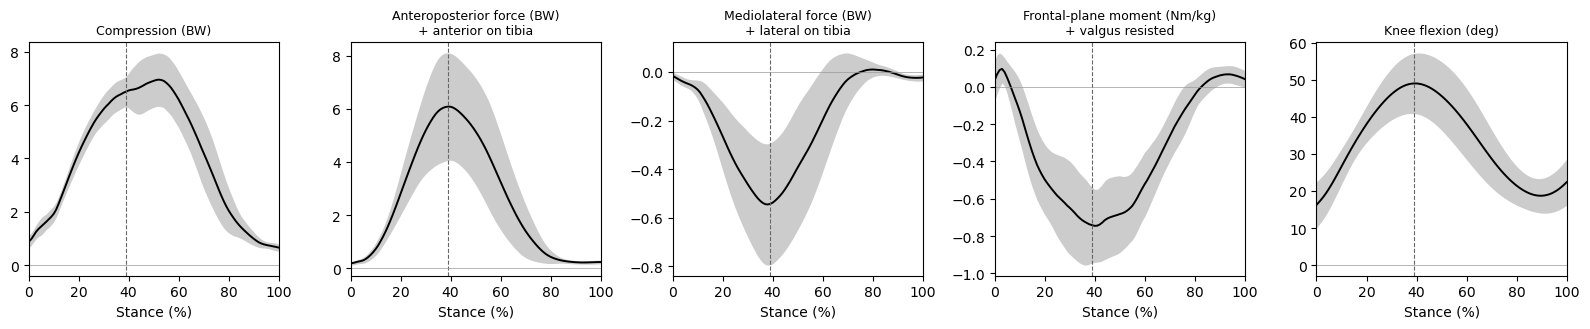

In [7]:
"""
SBMSB 2026 (SBMSB2026-007), revisão: extração da Tabela 1 e da Figura 1.

Lê os resultados JÁ EXISTENTES da FASE 3 (Dinâmica Inversa e Análise de Reação
Articular) e as forças de reação do solo da base de Nitschke et al. (2022).
NÃO executa o OpenSim e não altera nenhum resultado da dissertação.

Gera, na pasta de saída:
  tabela1_por_ciclo.csv      picos de cada um dos 30 ciclos
  tabela1_resumo.csv         mediana [IIQ] dos ciclos, média ± DP entre participantes e ICC(1)
  residuos_pelve.csv         resíduos da pelve na Dinâmica Inversa durante o apoio (% do peso)
  figura1_curvas.png/.pdf    curvas médias (± DP entre participantes) normalizadas pelo apoio

Uso:
  python -I sbmsb_tabela_figura_reacoes.py --resultados "C:/.../Resultados_FASE3" \
         --base "C:/.../Nitschke_Zenodo" --saida "C:/.../SBMSB_revisao" [--diagnostico]

Rode primeiro com --diagnostico: o script lista, para cada ensaio, os arquivos que
encontrou. Se algum não for encontrado, ajuste os padrões do bloco CONFIGURAÇÃO.
As definições (contato inicial a 20 N, aceitação de peso até o pico de flexão do
joelho, momento em valgo = mx > 0) são as mesmas da FASE 4.
"""
import argparse
import re
from pathlib import Path

import numpy as np
import pandas as pd

# ============================== CONFIGURAÇÃO ==============================
# Massas dos modelos escalonados (kg), as mesmas usadas na dissertação.
MASSAS = {"02": 67.11, "03": 58.79, "04": 84.19, "05": 64.88, "06": 77.66,
          "07": 57.73, "08": 65.71, "09": 97.23, "10": 71.79, "11": 67.75}
G = 9.81

# Padrões de busca (glob recursivo dentro da pasta de cada ensaio / da base).
PADRAO_JRA = "*ReactionLoads*.sto"          # saída da JointReaction
PADRAO_ID = "*nverse*ynamics*.sto"          # saída da Dinâmica Inversa (sua)
PADRAO_COORD = "*.mot"                      # coordenadas usadas na ID (filtradas ou não)
PADRAO_GRF = "*measured_GRFs*.mot"          # GRF da base (pé direito = ground_force_*)

# Colunas
COL_GRF_VY_DIR = "ground_force_vy"          # força vertical do pé direito
COL_JOELHO = "knee_angle_r"                 # no runMaD, flexão é NEGATIVA
SINAL_FLEXAO = -1.0                         # flexão positiva = -knee_angle_r
REGEX_JRA = r"_on_tibia_r_in_tibia_r_(fx|fy|fz|mx|my|mz)$"
COLS_RESIDUO_F = ["pelvis_tx_force", "pelvis_ty_force", "pelvis_tz_force"]
COLS_RESIDUO_M = ["pelvis_tilt_moment", "pelvis_list_moment", "pelvis_rotation_moment"]
LIMIAR_CONTATO = 20.0                       # N
N_PONTOS = 101                              # 0 a 100% do apoio
# ==========================================================================


def ler_opensim(caminho):
    with open(caminho, "r") as f:
        linhas = f.readlines()
    ini = next(i for i, l in enumerate(linhas) if "endheader" in l.lower()) + 1
    return pd.read_csv(caminho, sep=r"\s+", skiprows=ini)


def achar(pasta, padrao, contem=None):
    cands = sorted(Path(pasta).rglob(padrao))
    if contem:
        cands = [c for c in cands if contem in c.name or contem in str(c.parent)]
    return cands


def identificar_ensaios(raiz):
    """Cada arquivo de JRA define um ensaio; participante e ensaio vêm do caminho."""
    ensaios = []
    for jra in achar(raiz, PADRAO_JRA):
        txt = str(jra)
        p = re.search(r"[Pp]articipant[_ ]?0?(\d{1,2})|[Pp](\d{2})", txt)
        t = re.search(r"(\d{4})", jra.parent.name + "_" + jra.name)
        if not p or not t:
            continue
        pid = (p.group(1) or p.group(2)).zfill(2)
        ensaios.append({"participante": pid, "ensaio": t.group(1), "jra": jra,
                        "pasta": jra.parent})
    return ensaios


def janela_apoio(grf, t0_jra):
    """Contato inicial (vy > 20 N) a partir do início da JRA e retirada do pé."""
    t, vy = grf["time"].values, grf[COL_GRF_VY_DIR].values
    em_contato = (vy > LIMIAR_CONTATO) & (t >= t0_jra - 1e-9)
    i_ci = np.argmax(em_contato)
    i_to = i_ci + np.argmax(~em_contato[i_ci:]) if (~em_contato[i_ci:]).any() else len(t) - 1
    return t[i_ci], t[i_to]


def interp(t_orig, y, t_novo):
    return np.interp(t_novo, t_orig, y)


def icc1(df, col):
    """ICC de efeito único, modelo de efeitos aleatórios de um fator (Shrout; Fleiss, 1979)."""
    grupos = [g[col].dropna().values for _, g in df.groupby("participante")]
    k = np.mean([len(g) for g in grupos])
    n = len(grupos)
    media = np.mean(np.concatenate(grupos))
    msb = k * sum((g.mean() - media) ** 2 for g in grupos) / (n - 1)
    msw = sum(((g - g.mean()) ** 2).sum() for g in grupos) / (sum(len(g) for g in grupos) - n)
    with np.errstate(invalid="ignore", divide="ignore"):
        return (msb - msw) / (msb + (k - 1) * msw)


def processar(e, base, diagnostico=False):
    pid, tri, pasta = e["participante"], e["ensaio"], e["pasta"]
    ids = achar(pasta, PADRAO_ID)
    coords = [c for c in achar(base, f"*{tri}*.mot")
              if "inverse_methods" in c.name
              and re.search(rf"[Pp]articipant[_ ]?0?{int(pid)}(?!\d)", str(c))]
    grfs = achar(pasta, "grf_medidas_filtradas.mot") or \
           [g for g in achar(base, PADRAO_GRF, contem=tri)
            if re.search(rf"[Pp]articipant[_ ]?0?{int(pid)}(?!\d)", str(g))]
    if diagnostico:
        print(f"P{pid}/{tri}: JRA={e['jra'].name} | ID={[i.name for i in ids]} | "
              f"COORD={[c.name for c in coords]} | GRF={[str(g) for g in grfs]}")
        return None
    if not (ids and coords and grfs):
        raise FileNotFoundError(f"Arquivo ausente em P{pid}/{tri}; rode com --diagnostico.")

    massa = MASSAS[pid]
    pc = massa * G
    jra, idd = ler_opensim(e["jra"]), ler_opensim(ids[0])
    coo, grf = ler_opensim(coords[0]), ler_opensim(grfs[0])
    cols = {re.search(REGEX_JRA, c).group(1): c for c in jra.columns if re.search(REGEX_JRA, c)}

    t_ci, t_to = janela_apoio(grf, jra["time"].iloc[0])
    t = jra["time"].values
    m = (t >= t_ci) & (t <= t_to)
    ts = t[m]

    fx = jra[cols["fx"]].values[m]          # + = força anterior sobre a tíbia (solicitação posterior)
    comp = -jra[cols["fy"]].values[m]       # + = compressão
    fz = jra[cols["fz"]].values[m]          # + = lateral
    mx = jra[cols["mx"]].values[m]          # + = resiste a valgo; - = resiste a varo
    from scipy.signal import butter, filtfilt
    tc = coo["time"].values
    fs = 1.0 / np.median(np.diff(tc))
    b, a_ = butter(3, 15.0 / (fs / 2.0))
    joelho = filtfilt(b, a_, coo[COL_JOELHO].values)   # ensaio completo, como na dissertação
    flex = SINAL_FLEXAO * interp(tc, joelho, ts)

    # Aceitação de peso: contato inicial até o pico de flexão do joelho
    i_wa = int(np.argmax(flex))
    wa = slice(0, i_wa + 1)
    dur = ts[-1] - ts[0]

    def pico(sinal, janela=slice(None)):
        s = sinal[janela]
        i = int(np.argmax(s))
        return s[i], 100 * (ts[janela][i] - ts[0]) / dur, 1000 * (ts[janela][i] - ts[0])

    out = {"participante": pid, "ensaio": tri, "massa_kg": massa,
           "duracao_apoio_ms": 1000 * dur,
           "duracao_aceitacao_ms": 1000 * (ts[i_wa] - ts[0]),
           "aceitacao_pct_apoio": 100 * (ts[i_wa] - ts[0]) / dur,
           "flexao_joelho_CI_graus": flex[0],
           "flexao_joelho_pico_graus": flex[i_wa],
           # solicitação anterior da tíbia = -fx; valor máximo <= 0 indica ausência
           "solicitacao_anterior_max_N": np.max(-fx[wa]),
           }
    for nome, sinal, esc in [("compressao", comp, pc), ("AP_posterior", fx, pc),
                             ("ML_lateral", fz, pc), ("ML_medial", -fz, pc)]:
        v, pct, ms = pico(sinal)
        out[f"{nome}_pico_PC"] = v / esc
        out[f"{nome}_pico_Nkg"] = v / massa
        out[f"{nome}_instante_pct_apoio"] = pct
        out[f"{nome}_instante_ms"] = ms
        out[f"{nome}_flexao_no_pico_graus"] = flex[int(np.argmax(sinal))]
    for nome, sinal in [("valgo", mx), ("varo", -mx)]:
        v, pct, ms = pico(sinal, wa)
        out[f"{nome}_pico_aceitacao_Nmkg"] = v / massa
        out[f"{nome}_instante_ms"] = ms

    # Resíduos da pelve na Dinâmica Inversa durante o apoio
    mi = (idd["time"].values >= t_ci) & (idd["time"].values <= t_to)
    res = {"participante": pid, "ensaio": tri}
    for c in COLS_RESIDUO_F:
        if c in idd.columns:
            res[c + "_max_pctPC"] = 100 * np.max(np.abs(idd[c].values[mi])) / pc
            res[c + "_rms_pctPC"] = 100 * np.sqrt(np.mean(idd[c].values[mi] ** 2)) / pc
    for c in COLS_RESIDUO_M:
        if c in idd.columns:
            res[c + "_max_Nmkg"] = np.max(np.abs(idd[c].values[mi])) / massa

    # Curvas normalizadas (0 a 100% do apoio)
    tn = np.linspace(ts[0], ts[-1], N_PONTOS)
    curvas = {"comp": interp(ts, comp, tn) / pc, "ap": interp(ts, fx, tn) / pc,
              "ml": interp(ts, fz, tn) / pc, "mx": interp(ts, mx, tn) / massa,
              "flex": interp(ts, flex, tn)}
    return out, res, curvas


def resumo(df):
    linhas = []
    for col in [c for c in df.columns if c not in ("participante", "ensaio")]:
        x = df[col].astype(float)
        por_part = df.groupby("participante")[col].mean()
        linhas.append({"variavel": col,
                       "mediana_ciclos": x.median(), "q1": x.quantile(.25), "q3": x.quantile(.75),
                       "min": x.min(), "max": x.max(),
                       "media_participantes": por_part.mean(),
                       "dp_entre_participantes": por_part.std(ddof=1),
                       "ICC1": icc1(df, col) if col != "massa_kg" else np.nan})
    return pd.DataFrame(linhas)


def figura(curvas, df, saida):
    import matplotlib.pyplot as plt
    x = np.linspace(0, 100, N_PONTOS)
    wa = df.groupby("participante")["aceitacao_pct_apoio"].mean().mean()
    paineis = [("comp", "Compression (BW)"), ("ap", "Anteroposterior force (BW)\n+ anterior on tibia"),
               ("ml", "Mediolateral force (BW)\n+ lateral on tibia"),
               ("mx", "Frontal-plane moment (Nm/kg)\n+ valgus resisted"),
               ("flex", "Knee flexion (deg)")]
    fig, axs = plt.subplots(1, 5, figsize=(16, 3.4))
    for ax, (k, rot) in zip(axs, paineis):
        part = {}
        for (pid, _), c in curvas.items():
            part.setdefault(pid, []).append(c[k])
        medias = np.array([np.mean(v, axis=0) for v in part.values()])
        mu, sd = medias.mean(0), medias.std(0, ddof=1)
        ax.fill_between(x, mu - sd, mu + sd, color="0.8", lw=0)
        ax.plot(x, mu, color="k", lw=1.4)
        ax.axvline(wa, ls="--", color="0.4", lw=0.8)
        ax.axhline(0, color="0.6", lw=0.5)
        ax.set_xlabel("Stance (%)")
        ax.set_title(rot, fontsize=9)
        ax.set_xlim(0, 100)
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(Path(saida) / f"figura1_curvas.{ext}", dpi=300)
    print(f"Fim médio da aceitação de peso: {wa:.1f}% do apoio (linha tracejada).")


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--resultados", required=True)
    ap.add_argument("--base", required=True)
    ap.add_argument("--saida", required=True)
    ap.add_argument("--diagnostico", action="store_true")
    a = ap.parse_args()
    Path(a.saida).mkdir(parents=True, exist_ok=True)

    ensaios = identificar_ensaios(a.resultados)
    print(f"Ensaios encontrados: {len(ensaios)} (esperado: 30)")
    if a.diagnostico:
        for e in ensaios:
            processar(e, a.base, diagnostico=True)
        return

    linhas, residuos, curvas = [], [], {}
    for e in ensaios:
        o, r, c = processar(e, a.base)
        linhas.append(o); residuos.append(r); curvas[(e["participante"], e["ensaio"])] = c
    df = pd.DataFrame(linhas).sort_values(["participante", "ensaio"])
    df.to_csv(Path(a.saida) / "tabela1_por_ciclo.csv", index=False, sep=";", decimal=",")
    resumo(df).to_csv(Path(a.saida) / "tabela1_resumo.csv", index=False, sep=";", decimal=",")
    pd.DataFrame(residuos).to_csv(Path(a.saida) / "residuos_pelve.csv", index=False, sep=";", decimal=",")
    figura(curvas, df, a.saida)

    # Conferência com a dissertação (deve reproduzir a seção 3.2)
    print("Conferência: valgo mediana (esperado 0,114 Nm/kg):",
          round(df["valgo_pico_aceitacao_Nmkg"].median(), 3))
    print("Conferência: varo mediana (esperado 0,815 Nm/kg):",
          round(df["varo_pico_aceitacao_Nmkg"].median(), 3))
    print("Ciclos com solicitação anterior > 0 na aceitação (esperado 0):",
          int((df["solicitacao_anterior_max_N"] > 0).sum()))


import sys

RESULTADOS = r"C:\JG\opensim\Resultados_FASE3"
BASE       = r"C:\JG\opensim\Dados_Zenodo\Nitschke_et_al_Change_of_Direction_Marker_Simulation"
SAIDA      = r"G:\Meu Drive\MESTRADO\4º SEMESTRE\EVENTO - SBMSB DO PPGMSB 2026"

sys.argv = ["script", "--resultados", RESULTADOS, "--base", BASE,
            "--saida", SAIDA]
main()